# WebRTC QoE Intelligence — V1
Predicting subjective call-quality ratings from delay, jitter, and packet loss.

Data: [WebRTC-QoE dataset, Zenodo](https://zenodo.org/records/15836614), Bingol and colleagues. Uses only `Subjective_results_dataset.csv`. The original study defines ACR scores from 1 (Bad) to 5 (Excellent).

The analysis evaluates unseen network conditions using grouped cross-validation; individual users are not held out.

In [1]:
import sys
print("Python version:", sys.version.split()[0])


Python version: 3.14.7


In [2]:
from pathlib import Path
import pandas as pd

# Locate the repository from either its root or the notebooks folder.
project = Path.cwd().resolve()
if project.name == "notebooks":
    project = project.parent
if not (project / "data/raw/Subjective_results_dataset.csv").is_file():
    raise FileNotFoundError("Open this notebook from the project root or its notebooks folder.")
df = pd.read_csv(project / "data/raw/Subjective_results_dataset.csv")

print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
df.head()

Rows and columns: (15, 24)
Column names: ['Test Condition (TC)', 'Delay [ms]', 'Jitter [ms]', 'Packet Loss Rate [%]', 'User1', 'User2', 'User3', 'User4', 'User5', 'User6', 'User7', 'User8', 'User9', 'User10', 'User11', 'User12', 'User13', 'User14', 'User15', 'User16', 'User17', 'User18', 'User19', 'User20']


,Test Condition (TC),Delay [ms],Jitter [ms],Packet Loss Rate [%],User1,User2,User3,User4,User5,User6,User7,User8,User9,User10,User11,User12,User13,User14,User15,User16,User17,User18,User19,User20
0,1,0,0,0,5,4,3,5,3,3,5,5,3,3,3,4,4,4,3,5,3,5,4,4
1,2,500,0,0,4,3,3,4,3,2,4,5,5,3,1,5,3,5,3,4,3,4,3,5
2,3,1000,0,0,4,4,3,4,3,3,5,4,5,3,3,5,3,4,3,4,4,4,4,3
3,4,500,500,0,2,2,3,4,3,3,5,3,4,1,3,4,4,4,4,3,4,4,4,4
4,5,1000,500,0,3,3,3,4,2,3,4,4,4,3,3,5,4,4,3,3,3,3,3,4


## Same ratings, a different layout
Before, each condition has 20 rating columns. After, each rating gets its own row.

For condition 1, User1 rated 5, User2 rated 4, and User3 rated 3. The next cell shows these same three ratings in the new layout.

`melt` stacks the user columns into a single Rating column and records the user name alongside it. The original `df` stays unchanged.

In [3]:
# Keep the condition and its three network settings attached to every rating.
condition_columns = [
    "Test Condition (TC)",
    "Delay [ms]",
    "Jitter [ms]",
    "Packet Loss Rate [%]",
]
user_columns = [f"User{i}" for i in range(1, 21)]

# Turn the 20 user columns into two columns: User and Rating.
ratings = df.melt(
    id_vars=condition_columns,
    value_vars=user_columns,
    var_name="User",
    value_name="Rating",
)

print("Before:", df.shape, "— one row per condition")
print("After:", ratings.shape, "— one row per user's rating of a condition")

# Show the first three users for condition 1.
ratings.loc[
    (ratings["Test Condition (TC)"] == 1)
    & ratings["User"].isin(["User1", "User2", "User3"])
].reset_index(drop=True)


Before: (15, 24) — one row per condition
After: (300, 6) — one row per user's rating of a condition


,Test Condition (TC),Delay [ms],Jitter [ms],Packet Loss Rate [%],User,Rating
0,1,0,0,0,User1,5
1,1,0,0,0,User2,4
2,1,0,0,0,User3,3


There are still only **15 different network conditions**, with 20 ratings each. Later, all ratings for a condition must stay together in training or testing. Only delay, jitter, and packet loss will be predictors; Rating will be the target.

## Check the data before modeling
This checks whether values are missing, whether ratings are valid, and whether each condition/user pair appears only once. Repeated network settings across different users are expected; a repeated condition/user pair would need investigation.

These checks work whether we later evaluate individual ratings or condition averages. They do not train a model.

In [4]:
# Check the table before splitting data or training a model.
features = ["Delay [ms]", "Jitter [ms]", "Packet Loss Rate [%]"]

checks = pd.Series({
    "Total rating rows": len(ratings),
    "Missing values (all columns)": int(ratings.isna().sum().sum()),
    "Ratings outside 1–5 or missing": int((~ratings["Rating"].isin([1, 2, 3, 4, 5])).sum()),
    "Repeated condition/user pairs": int(ratings.duplicated(["Test Condition (TC)", "User"]).sum()),
    "Unique network conditions": len(ratings[features].drop_duplicates()),
    "Fewest ratings per network condition": int(ratings.groupby(features).size().min()),
    "Most ratings per network condition": int(ratings.groupby(features).size().max()),
}, name="Result")
checks.to_frame()


,Result
Total rating rows,300
Missing values (all columns),0
Ratings outside 1–5 or missing,0
Repeated condition/user pairs,0
Unique network conditions,15
Fewest ratings per network condition,20
Most ratings per network condition,20


## Hold out whole network conditions
Training data is used to learn the relationship. Test data is reserved to evaluate predictions on unseen network settings.

We keep all 20 ratings for each setting together: 12 conditions (240 ratings) for training and 3 conditions (60 ratings) for testing. A fixed random seed makes the selection repeatable.

This split uses only network settings, not scores. It works for either individual-rating evaluation or condition-average evaluation because any averaging can happen separately within these partitions. The same users occur on both sides: this is a test of new conditions, not new users.

Three test conditions give a limited, split-dependent estimate. Do not change the seed to improve results or tune a model using test scores.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

# Ratings with the same three network settings receive the same group number.
condition_groups = ratings.groupby(features, sort=True).ngroup()

# Hold out 20% of the 15 conditions: 3 test conditions, 12 training conditions.
# A fixed seed makes this split reproducible; we do not search for an easier test set.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(splitter.split(ratings, groups=condition_groups))

train_ratings = ratings.iloc[train_index].copy()
test_ratings = ratings.iloc[test_index].copy()

# Check actual network settings, not just condition identifiers.
train_conditions = set(map(tuple, train_ratings[features].to_numpy()))
test_conditions = set(map(tuple, test_ratings[features].to_numpy()))
overlap = train_conditions & test_conditions
assert not overlap, "A network condition appears in both training and testing!"

print(f"Training: {len(train_conditions)} conditions, {len(train_ratings)} ratings")
print(f"Testing: {len(test_conditions)} conditions, {len(test_ratings)} ratings")
print(f"Shared conditions: {len(overlap)}")
print("Training condition IDs:", sorted(train_ratings["Test Condition (TC)"].unique().tolist()))
print("Test condition IDs:", sorted(test_ratings["Test Condition (TC)"].unique().tolist()))

# Display only held-out network settings, without inspecting their scores.
test_ratings[condition_columns].drop_duplicates().sort_values("Test Condition (TC)").reset_index(drop=True)


Training: 12 conditions, 240 ratings
Testing: 3 conditions, 60 ratings
Shared conditions: 0
Training condition IDs: [2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15]
Test condition IDs: [1, 3, 13]


,Test Condition (TC),Delay [ms],Jitter [ms],Packet Loss Rate [%]
0,1,0,0,0
1,3,1000,0,0
2,13,1000,0,30


## Baseline: always predict the training average
Before fitting linear regression, establish a simple reference. This baseline ignores delay, jitter, and loss and predicts the overall average of the **training** ratings for every test example. Test ratings do not influence that average.

For this step we continue the existing individual-rating workflow: **MAE (mean absolute error)** is the average distance between a prediction and each individual test rating, measured in rating points. Lower is better. It is not error against condition averages and does not measure personalized prediction.

The later regression must be evaluated on the same held-out conditions and targets for a fair comparison. A lower error would improve on this baseline for this split; it would not alone establish broad performance. We will not select models or adjust the split based on test results.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Only network settings are inputs; each observed Rating is a target.
X_train = train_ratings[features]
y_train = train_ratings["Rating"]
X_test = test_ratings[features]
y_test = test_ratings["Rating"]

# Learn one number: the average of the 240 training ratings.
# This baseline ignores the input values when predicting.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# MAE: average absolute distance from each actual individual test rating.
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
print(f"Training average: {y_train.mean():.3f}")
print(f"Baseline predicts {baseline_predictions[0]:.3f} for every test rating.")
print(f"Test MAE against individual ratings: {baseline_mae:.3f} rating points")

# Preview three people's ratings under the same held-out condition.
baseline_examples = test_ratings[condition_columns + ["User", "Rating"]].copy()
baseline_examples["Baseline prediction"] = baseline_predictions
baseline_examples["Absolute error"] = (
    baseline_examples["Rating"] - baseline_examples["Baseline prediction"]
).abs()
first_test_condition = sorted(test_ratings["Test Condition (TC)"].unique())[0]
baseline_examples.loc[
    (baseline_examples["Test Condition (TC)"] == first_test_condition)
    & baseline_examples["User"].isin(["User1", "User2", "User3"])
].reset_index(drop=True).round(3)


Training average: 2.717
Baseline predicts 2.717 for every test rating.
Test MAE against individual ratings: 1.044 rating points


,Test Condition (TC),Delay [ms],Jitter [ms],Packet Loss Rate [%],User,Rating,Baseline prediction,Absolute error
0,1,0,0,0,User1,5,2.717,2.283
1,1,0,0,0,User2,4,2.717,1.283
2,1,0,0,0,User3,3,2.717,0.283


## Linear regression: let predictions depend on network settings
Unlike the constant baseline, this model learns an intercept and a weight for each of delay, jitter, and packet loss. It estimates a score by adding their weighted contributions. Only training data is used to fit these weights.

We compare both models against the same 60 individual test ratings using MAE; lower is better. The prediction is an expected rating, not a personalized score. This is one held-out split with only three conditions, so improvement here is limited evidence, not a guarantee of broader accuracy. We do not tune the model using these test results.

In [7]:
from sklearn.linear_model import LinearRegression

# Learn a relationship between the three network inputs and ratings.
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Evaluate once on the same held-out ratings used for the baseline.
linear_predictions = linear_model.predict(X_test)
linear_mae = mean_absolute_error(y_test, linear_predictions)

comparison = pd.DataFrame({
    "Model": ["Training-mean baseline", "Linear regression"],
    "Test MAE (individual rating points)": [baseline_mae, linear_mae],
})
print(f"Linear regression reduces MAE by {baseline_mae - linear_mae:.3f} rating points on this split.")
print(f"Test prediction range: {linear_predictions.min():.3f} to {linear_predictions.max():.3f}")
print("Predictions outside 1–5:", int(((linear_predictions < 1) | (linear_predictions > 5)).sum()))
comparison.round(3)


Linear regression reduces MAE by 0.355 rating points on this split.
Test prediction range: 1.991 to 3.949
Predictions outside 1–5: 0


,Model,Test MAE (individual rating points)
0,Training-mean baseline,1.044
1,Linear regression,0.689


## Grouped 5-fold cross-validation
Our first result used one split. Now we evaluate the same fixed models five times, each time holding out 3 of the 15 conditions and training on the other 12. All 20 ratings for a condition stay together. Each condition is tested once.

The folds are shuffled with a fixed seed chosen before viewing results. Each fold learns its own baseline average and regression weights from training data only. Positive MAE reduction means linear regression did better in that fold.

This uses the entire dataset, including the earlier holdout, so there is no separate untouched final test set. We are evaluating fixed models, not tuning or choosing settings based on these results. The same participants occur in training and testing; this evaluates held-out conditions, not new users.

In [8]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Use all 15 conditions for this broader evaluation.
# Each condition is held out once; the earlier holdout is no longer a separate final test.
X_cv = ratings[features]
y_cv = ratings["Rating"]
groups_cv = ratings.groupby(features, sort=True).ngroup()
cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []
oof_baseline = np.full(len(ratings), np.nan)
oof_linear = np.full(len(ratings), np.nan)
test_counts = np.zeros(len(ratings), dtype=int)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_cv, y_cv, groups_cv), start=1):
    # Verify no network setting appears on both sides of this fold.
    training_groups = set(groups_cv.iloc[train_idx])
    testing_groups = set(groups_cv.iloc[test_idx])
    assert training_groups.isdisjoint(testing_groups)
    assert len(training_groups) == 12 and len(testing_groups) == 3

    # Fresh models: each learns only from this fold's training ratings.
    fold_baseline = DummyRegressor(strategy="mean")
    fold_linear = LinearRegression()
    fold_baseline.fit(X_cv.iloc[train_idx], y_cv.iloc[train_idx])
    fold_linear.fit(X_cv.iloc[train_idx], y_cv.iloc[train_idx])
    baseline_pred = fold_baseline.predict(X_cv.iloc[test_idx])
    linear_pred = fold_linear.predict(X_cv.iloc[test_idx])

    baseline_error = mean_absolute_error(y_cv.iloc[test_idx], baseline_pred)
    linear_error = mean_absolute_error(y_cv.iloc[test_idx], linear_pred)
    fold_results.append({
        "Fold": fold,
        "Held-out condition IDs": ", ".join(map(str, sorted(
            ratings.iloc[test_idx]["Test Condition (TC)"].unique().tolist()
        ))),
        "Training ratings": len(train_idx),
        "Test ratings": len(test_idx),
        "Baseline MAE": baseline_error,
        "Linear MAE": linear_error,
        "MAE reduction": baseline_error - linear_error,
    })
    oof_baseline[test_idx] = baseline_pred
    oof_linear[test_idx] = linear_pred
    test_counts[test_idx] += 1

# Every rating receives exactly one prediction from a model that did not train on its condition.
assert (test_counts == 1).all()
assert np.isfinite(oof_baseline).all() and np.isfinite(oof_linear).all()
cv_results = pd.DataFrame(fold_results)
print("Verified: 5 folds, no shared conditions within folds, every rating tested once.")
cv_results.round(3)


Verified: 5 folds, no shared conditions within folds, every rating tested once.


,Fold,Held-out condition IDs,Training ratings,Test ratings,Baseline MAE,Linear MAE,MAE reduction
0,1,"1, 3, 13",240,60,1.044,0.689,0.355
1,2,"10, 12, 14",240,60,0.978,0.741,0.238
2,3,"6, 11, 15",240,60,0.780,0.633,0.147
3,4,"7, 8, 9",240,60,0.588,0.561,0.027
4,5,"2, 4, 5",240,60,0.997,0.732,0.265


### Read the summary
Mean fold MAE is the average error across the five folds. The standard deviation describes how much those fold errors vary; it is not a confidence interval. Out-of-fold predictions are made only when the relevant condition is held out.

Each fold has 60 ratings, so mean fold MAE and overall out-of-fold MAE agree. With only 15 conditions, results remain limited and do not establish performance on arbitrary new network settings.

In [9]:
# MAE is measured against individual ratings, in rating points.
cv_summary = pd.DataFrame({
    "Model": ["Training-mean baseline", "Linear regression"],
    "Mean fold MAE": [cv_results["Baseline MAE"].mean(), cv_results["Linear MAE"].mean()],
    "Fold MAE standard deviation": [cv_results["Baseline MAE"].std(), cv_results["Linear MAE"].std()],
    "Overall out-of-fold MAE": [
        mean_absolute_error(y_cv, oof_baseline),
        mean_absolute_error(y_cv, oof_linear),
    ],
})
print("Folds where linear regression has lower MAE:", int((cv_results["MAE reduction"] > 0).sum()), "of 5")
print("Out-of-fold linear predictions outside 1–5:", int(((oof_linear < 1) | (oof_linear > 5)).sum()))
cv_summary.round(3)


Folds where linear regression has lower MAE: 5 of 5
Out-of-fold linear predictions outside 1–5: 0


,Model,Mean fold MAE,Fold MAE standard deviation,Overall out-of-fold MAE
0,Training-mean baseline,0.877,0.191,0.877
1,Linear regression,0.671,0.075,0.671


## See predictions condition by condition
Each dot represents one network condition. Its horizontal position is the average of that condition’s 20 human ratings; its vertical position is the prediction made while that condition was held out. Numbers identify conditions.

The dashed diagonal is perfect agreement with the **condition average**. Dots above it mean overprediction; dots below it mean underprediction. Even a dot exactly on the line can still have errors against individual people’s ratings. Our earlier MAE remains an individual-rating metric.

The baseline can differ between folds because each fold has its own training average. These plots use existing out-of-fold predictions: neither model is refitted here.

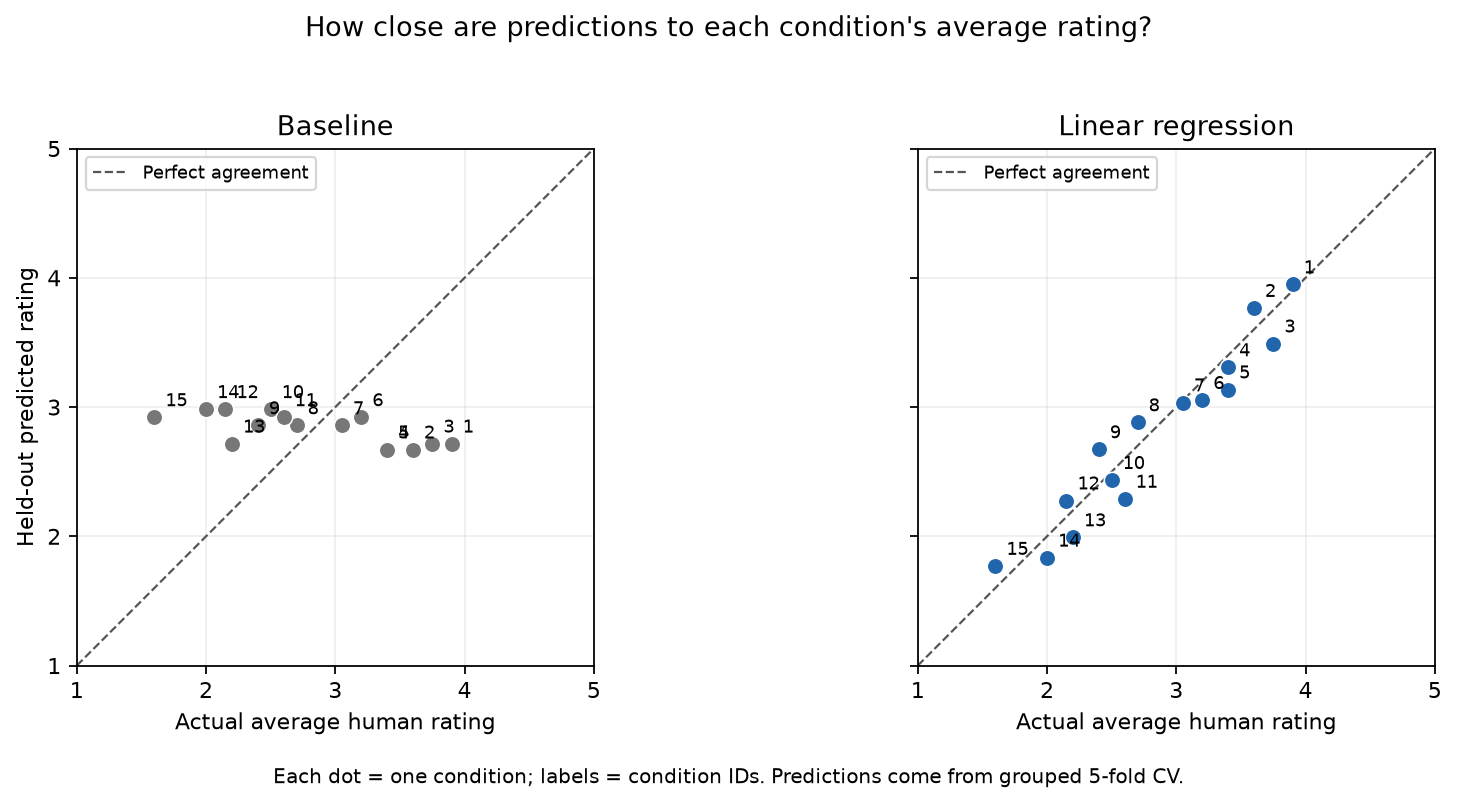

In [10]:
import matplotlib.pyplot as plt

# Every prediction below was made while its entire condition was held out.
condition_predictions = ratings[condition_columns + ["Rating"]].copy()
condition_predictions["Linear prediction"] = oof_linear
condition_predictions["Baseline prediction"] = oof_baseline
condition_summary = (
    condition_predictions.groupby(condition_columns, as_index=False)
    .agg(
        actual_mean=("Rating", "mean"),
        linear_prediction=("Linear prediction", "mean"),
        baseline_prediction=("Baseline prediction", "mean"),
    )
    .sort_values("Test Condition (TC)")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, column, title, color in zip(
    axes,
    ["baseline_prediction", "linear_prediction"],
    ["Baseline", "Linear regression"],
    ["#777777", "#2166ac"],
):
    ax.plot([1, 5], [1, 5], "--", color="#555555", linewidth=1, label="Perfect agreement")
    ax.scatter(condition_summary["actual_mean"], condition_summary[column],
               color=color, s=55, edgecolors="white", linewidth=0.7, zorder=3)
    for _, row in condition_summary.iterrows():
        ax.annotate(str(int(row["Test Condition (TC)"])),
                    (row["actual_mean"], row[column]),
                    xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.set(title=title, xlabel="Actual average human rating", xlim=(1, 5), ylim=(1, 5))
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Held-out predicted rating")
fig.suptitle("How close are predictions to each condition's average rating?")
fig.text(0.5, 0.02, "Each dot = one condition; labels = condition IDs. Predictions come from grouped 5-fold CV.",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 0.95])
(project / "reports").mkdir(exist_ok=True)
fig.savefig(project / "reports/condition-predictions.png", dpi=160, bbox_inches="tight")
plt.show()


## What did the model learn? Coefficients
A coefficient is the amount the predicted rating changes when one input increases by one unit, with the other inputs held fixed. A negative coefficient means a lower predicted rating. The intercept is the predicted score when all three inputs are zero.

We inspect the **original model trained on 12 conditions**, not the final fold model left in the CV loop. Each CV fold fitted its own coefficients; the CV graph combines predictions from those different models. No new model is fitted here.

Delay and jitter are measured in milliseconds. To make their effects readable, show changes per 100 ms. Packet loss uses percentage points: from 15% to 16% is one percentage point.

These coefficients describe an additive linear relationship fitted to this small dataset. They are not proof of causation or universal effects. Raw coefficient sizes use different units and should not be ranked as feature importance. The model assumes constant slopes and no interactions; some hypothetical input combinations were not observed.

In [11]:
# Inspect the original regression fitted on 12 training conditions.
# CV trained five separate models; this table describes the original model only.
coefficient_table = pd.DataFrame({
    "Input": features,
    "Coefficient per original unit": linear_model.coef_,
    "Change in input": ["+100 ms delay", "+100 ms jitter", "+1 percentage point packet loss"],
    "Predicted rating change": linear_model.coef_ * np.array([100, 100, 1]),
})
print(f"Intercept (prediction at zero delay, jitter, and loss): {linear_model.intercept_:.3f}")
print("Each change below assumes the other two inputs stay the same.")
coefficient_table.round(4)


Intercept (prediction at zero delay, jitter, and loss): 3.949
Each change below assumes the other two inputs stay the same.


,Input,Coefficient per original unit,Change in input,Predicted rating change
0,Delay [ms],-0.0005,+100 ms delay,-0.0458
1,Jitter [ms],-0.0006,+100 ms jitter,-0.0612
2,Packet Loss Rate [%],-0.0500,+1 percentage point packet loss,-0.0500


### Build one prediction by adding the pieces
Predicted rating = intercept + delay contribution + jitter contribution + packet-loss contribution. Each contribution is the input value multiplied by its coefficient. The calculation uses full-precision values, even though the displayed table rounds them.

In [12]:
# A concrete example of the formula, using network settings within the observed range.
example_settings = pd.DataFrame([[500, 0, 15]], columns=features)
contributions = example_settings.iloc[0].to_numpy() * linear_model.coef_
formula_parts = pd.DataFrame({
    "Part of prediction": ["Starting value (intercept)", "Delay contribution", "Jitter contribution", "Packet-loss contribution"],
    "Rating points": [linear_model.intercept_, *contributions],
})
manual_prediction = float(linear_model.intercept_ + contributions.sum())
model_prediction = float(linear_model.predict(example_settings)[0])
assert np.isclose(manual_prediction, model_prediction)
print("Example: delay 500 ms, jitter 0 ms, packet loss 15%")
print(f"Add the four parts below: predicted rating = {model_prediction:.3f}")
formula_parts.round(3)


Example: delay 500 ms, jitter 0 ms, packet loss 15%
Add the four parts below: predicted rating = 2.970


,Part of prediction,Rating points
0,Starting value (intercept),3.949
1,Delay contribution,-0.229
2,Jitter contribution,-0.000
3,Packet-loss contribution,-0.750


## Final model artifact
After grouped cross-validation, refit the fixed linear-regression specification on all 300 ratings across 15 conditions for future use. This final model has its own coefficients, distinct from the original holdout model and the five CV models.

Save the model with input names, units, package versions, dataset fingerprint, and evaluation provenance. Verify that reloading preserves predictions. The held-out CV results remain our performance estimate; fitting all data is not a new evaluation.

In [13]:
import hashlib
import json
import platform
import joblib
import sklearn

# Refit the fixed model specification on all available ratings after evaluation.
# Keep it separate from the original holdout model and the CV fold models.
final_model = LinearRegression()
final_model.fit(ratings[features], ratings["Rating"])

model_directory = project / "models"
model_directory.mkdir(exist_ok=True)
model_path = model_directory / "qoe_linear_v1.joblib"
metadata_path = model_directory / "qoe_linear_v1_metadata.json"

# Retain the exact input names/order and the meaning of the target with the model.
model_bundle = {
    "model": final_model,
    "features": features,
    "target": "Expected individual subjective rating on the 1–5 scale; not personalized",
}
joblib.dump(model_bundle, model_path)

metadata = {
    "model": "Ordinary least-squares LinearRegression",
    "training_ratings": len(ratings),
    "network_conditions": len(ratings[features].drop_duplicates()),
    "features": features,
    "units": ["milliseconds", "milliseconds", "percentage points (15 means 15%)"],
    "coefficients": dict(zip(features, final_model.coef_.tolist())),
    "intercept": float(final_model.intercept_),
    "observed_input_values": {name: sorted(ratings[name].unique().tolist()) for name in features},
    "source_csv_sha256": hashlib.sha256((project / "data/raw/Subjective_results_dataset.csv").read_bytes()).hexdigest(),
    "evaluation": {
        "method": "Grouped 5-fold CV, shuffled with seed 42; groups are network-setting combinations",
        "target": "Individual ratings",
        "linear_mae": float(mean_absolute_error(y_cv, oof_linear)),
        "baseline_mae": float(mean_absolute_error(y_cv, oof_baseline)),
        "note": "CV scores come from held-out fold models, not from scoring this final fit on training data.",
    },
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "limitations": "15 conditions; same users across folds; no independent final test set; no personalized or causal claims; extrapolation unvalidated; predictions not clipped.",
}
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")

# Verify that saving and reloading preserves predictions, using our own saved artifact.
reloaded_bundle = joblib.load(model_path)
np.testing.assert_allclose(
    final_model.predict(ratings[features]),
    reloaded_bundle["model"].predict(ratings[reloaded_bundle["features"]]),
)
print(f"Final model fitted on {len(ratings)} ratings across {metadata['network_conditions']} conditions.")
print("Saved:", model_path.name)
print("Saved:", metadata_path.name)
print("Reload check passed: predictions are unchanged.")


Final model fitted on 300 ratings across 15 conditions.
Saved: qoe_linear_v1.joblib
Saved: qoe_linear_v1_metadata.json
Reload check passed: predictions are unchanged.


## Findings and limitations

### What we asked
Can delay, jitter, and packet loss help estimate a human quality rating for a network condition excluded from training?

### What we evaluated
The dataset contains **300 individual ratings from 20 users across 15 network conditions**. Inputs were only delay, jitter, and packet loss. The target was each observed 1–5 rating; predictions estimate expected quality rather than a specific person's preferences.

We compared a training-mean baseline with ordinary linear regression using **grouped 5-fold cross-validation**. Each fold trained on 12 conditions and tested on 3. Every condition was tested once, and no condition appeared in both training and testing within a fold.

### Main result
| Model | Mean cross-validation MAE |
|---|---:|
| Training-mean baseline | 0.877 rating points |
| Linear regression | 0.671 rating points |

Regression reduced average absolute error by **0.206 rating points**, approximately **23.5% relative to the baseline**, and had lower error in all five folds. Its fold MAEs ranged from **0.561 to 0.741**. The improvement was small in one fold, so its size depends on the held-out conditions.

**Plain-language interpretation:** For this dataset and evaluation, using network settings gave predictions closer to individual human ratings than always guessing the training average. A lower MAE means smaller average prediction errors; it is not an accuracy percentage.

### What the plots and coefficients tell us
The plots compare held-out predictions with each condition's average rating. They help show where predictions are high or low, but are not the same metric as individual-rating MAE. The original 12-condition model's coefficients are negative for delay, jitter, and loss, holding the other inputs fixed. These describe its fitted relationship; they do not prove causal effects. Each cross-validation fold fitted a separate model.

### Limits of this result
- There are only **15 independent network-setting combinations**, not 300 distinct conditions. Repeated ratings do not remove that limitation.
- The same users appear in training and testing. We evaluated held-out conditions, not generalization to new users.
- Cross-validation uses all 15 conditions; the earlier holdout is no longer a separate untouched final test set. These fixed models were evaluated without tuning or seed searches.
- This is one five-fold partition. Fold variability is descriptive, not a confidence interval or proof of performance on arbitrary new settings.
- Treating 1–5 ratings numerically assumes equal-sized steps between scores. Linear regression also assumes an additive relationship with constant slopes and no interactions.
- No held-out prediction fell outside 1–5 here, but linear regression does not guarantee that for future inputs. Avoid interpreting extrapolations as validated predictions.
- Individual preferences are not inputs, so this model cannot personalize scores. Only the provided subjective dataset was used; V2 telemetry was not analyzed.

### Current conclusion
V1 provides evidence that these three network inputs improve prediction over a constant baseline within this small dataset. It is a starting benchmark, not a validated production quality estimator.
